# Volume Profile（成交量按价格分布）

规范 `docs/volume_profile_spec.md`，决策 0017。计算逻辑在 `trader.analytics.volume_profile`，本 notebook 只设参数和展示。

**用法**：改参数单元格，然后 *Run → Run All Cells*。每天的细网格第一次计算后缓存在 `data/profiles/`，之后很快；
第 3、4 节的对比要用另外几套参数各算一次，第一次约几分钟。

**名词**

| 名称 | 含义 |
|---|---|
| POC | 成交量最大的价格格子 |
| 价值区 VAH / VAL | 从 POC 向两侧扩展，包含 70% 成交量的价格区间的上沿 / 下沿 |
| HVN / LVN | 分布上的成交量高峰 / 两个高峰之间的低谷（平滑后） |
| 格子 | 默认 ADR × 0.02（一天约 50 格）；ADR = 过去 21 天常规时段振幅的中位数 |

**时点**：交易日 T 开盘前能用的只有 T−1 及之前完整交易日的数据；当天的 developing（盘中滚动的 POC / 价值区）
在每个时刻只用该时刻之前已收盘的 1 秒 bar。价格一律是 T 当天的实际价格（拆股前的日子已换算）。
只用常规时段，默认剔除收盘竞价（15:59:59–16:00:00），计算前删除坏数据时段、修正离群成交。


In [1]:
# ===== 参数 =====
from trader.analytics.volume_profile import ProfileParams

symbol = "NVDA"  # 第 1、2 节看哪只证券、哪一天
day = "2026-10-15"
symbols = ["NVDA", "AMD", "META", "TSLA", "SPY", "QQQ"]  # 第 3–5 节统计用
start_date = "2026-07-01"
end_date = "2026-10-16"
params = ProfileParams()  # 例如 ProfileParams(distribution="close", bin_adr_frac=0.05)

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from trader.analytics.volume_profile import VolumeProfile
from trader.analytics.volume_profile import plots as P


def show(fig):
    display(fig)
    plt.close(fig)


pd.set_option("display.width", 200)
vpf = VolumeProfile(params)

## 1. 单日图

左边：1 分钟收盘价（含盘前）、当天 VWAP、developing POC 的轨迹（橙线）、前一日 POC（红）/ VAH / VAL（蓝虚线）、
5 日复合价值区（绿色带）、盘前高低点（棕色点线）。右边：当天截至收盘的分布（橙）和前一日的分布（灰）。

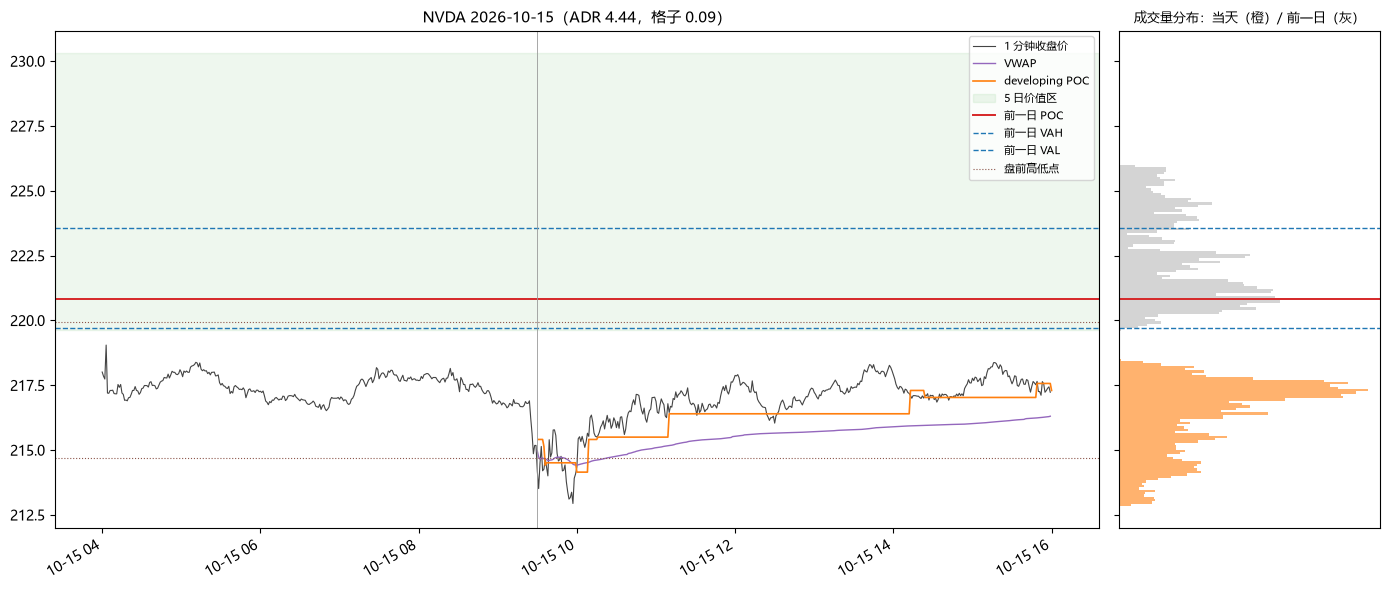

In [3]:
show(P.fig_day(vpf, symbol, day))

开盘前可用的各种 Profile 的关键价位（与 `uv run trader profile levels` 相同）。`n_days` 是实际用到的交易日数。

In [4]:
lv = pd.DataFrame([vpf.get_levels(symbol, day, k, **kw) for k, kw in vpf.default_windows()])
cols = [
    "profile_type",
    "params",
    "poc",
    "vah",
    "val",
    "va_width_adr",
    "poc_position",
    "n_hvn",
    "hvn",
    "lvn",
    "n_days",
    "bin_size",
    "adr",
]
display(lv[cols].round(3))
print("尚未回测的 POC（过去 20 个交易日）：")
display(vpf.naked_at(symbol, day))

,profile_type,params,poc,vah,val,va_width_adr,poc_position,n_hvn,hvn,lvn,n_days,bin_size,adr
0,daily,{},220.81,223.55,219.69,0.869,0.184,2,"[220.81, 224.5]",[222.79],1,0.09,4.44
1,composite,"{""n"": 3}",226.48,228.50,222.84,1.275,0.742,2,"[220.81, 226.48]",[222.79],3,0.09,4.44
2,composite,"{""n"": 5}",226.48,230.30,219.64,2.401,0.392,4,"[220.81, 226.48, 229.63, 234.22]","[222.79, 229.0, 233.23]",5,0.09,4.44
3,composite,"{""n"": 10}",237.01,243.35,229.59,3.099,0.732,3,"[226.48, 230.62, 237.01]","[228.91, 233.23]",10,0.09,4.44
4,composite,"{""n"": 20}",230.53,232.91,219.33,3.059,0.510,4,"[219.55, 225.31, 230.53, 237.01]","[220.09, 226.21, 233.32]",20,0.09,4.44
5,decay,"{""half_life"": 3}",226.48,231.38,219.78,2.613,0.510,4,"[220.81, 226.48, 230.53, 237.01]","[222.79, 229.0, 233.23]",30,0.09,4.44
6,decay,"{""half_life"": 5}",230.53,233.63,217.71,3.586,0.645,4,"[220.81, 225.4, 230.53, 237.01]","[222.79, 229.0, 233.23]",50,0.09,4.44
7,anchored,"{""anchor"": ""auto"", ""anchor_time"": ""2026-10-02 ...",237.01,243.35,229.41,3.140,0.732,3,"[226.48, 229.63, 237.01]","[229.0, 233.23]",9,0.09,4.44
8,premarket,{},216.85,218.15,216.63,0.342,0.413,1,[216.76],[],1,0.09,4.44
9,postmarket,{},221.71,222.03,218.79,0.730,0.928,2,"[218.92, 221.8]",[219.55],1,0.09,4.44


尚未回测的 POC（过去 20 个交易日）：


,symbol,poc_date,poc,touched_date,touched_time,poc_now
1,NVDA,2026-09-18,219.545,None,NaT,219.545
13,NVDA,2026-10-06,242.230,None,NaT,242.230
16,NVDA,2026-10-09,229.540,None,NaT,229.540
19,NVDA,2026-10-14,220.810,None,NaT,220.810


In [5]:
dev = vpf.get_developing(symbol, day)
display(dev.iloc[[0, 14, 29, 59, 119, 239, len(dev) - 1]])

,symbol,date,time,dpoc,dvah,dval,cum_volume,stable
0,NVDA,2026-10-15,2026-10-15 09:31:00-04:00,215.41,215.74,214.83,4.931735e+06,False
14,NVDA,2026-10-15,2026-10-15 09:45:00-04:00,214.51,215.45,214.11,1.791652e+07,True
29,NVDA,2026-10-15,2026-10-15 10:00:00-04:00,214.15,215.63,213.93,2.691622e+07,True
59,NVDA,2026-10-15,2026-10-15 10:30:00-04:00,215.50,215.90,214.02,3.738255e+07,True
119,NVDA,2026-10-15,2026-10-15 11:30:00-04:00,216.40,217.16,214.38,5.489844e+07,True
239,NVDA,2026-10-15,2026-10-15 13:30:00-04:00,216.40,217.70,214.92,7.299663e+07,True
389,NVDA,2026-10-15,2026-10-15 16:00:00-04:00,217.30,218.24,215.46,1.031257e+08,True


## 2. 多窗口对比

同一天开盘前，前一日、5 日、20 日、衰减（半衰期 3 天）Profile 并排。几个窗口的 POC / 价值区边缘靠得近的价位，
是后续研究"支撑阻力是否更强"的候选。

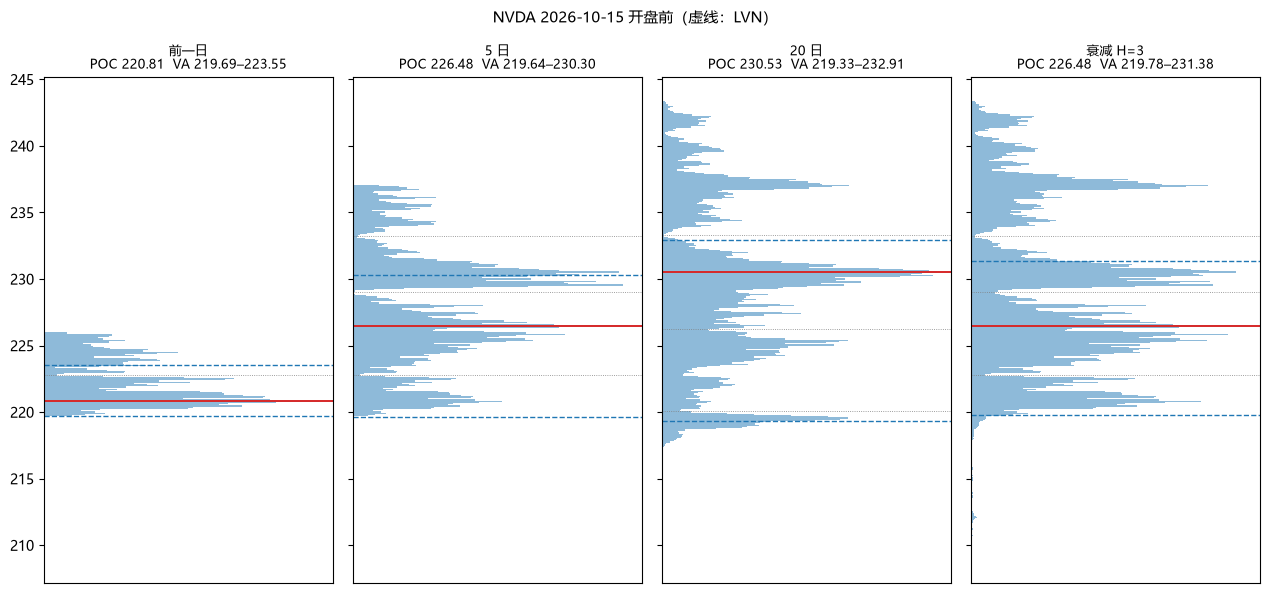

In [6]:
show(P.fig_windows(vpf, symbol, day))

## 3. 方法敏感性：bar 粒度与分配方法

每天自己的 Profile 用两套参数各算一次，比较 POC / VAH / VAL 的差（ADR 倍数；一个格子 = 0.02 ADR）。
基准是 1 秒 bar + `uniform`（成交量平均分到 bar 的高低价之间）。1 分钟、5 分钟 bar 由同一份清洗后的 1 秒 bar 合成，
差别只来自 bar 粒度。

,天数,poc 中位数,poc 90 分位,poc >0.1 ADR,vah 中位数,vah 90 分位,vah >0.1 ADR,val 中位数,val 90 分位,val >0.1 ADR
对比,,,,,,,,,,
1 分钟 bar,456,0.00,0.060,0.070,0.00,0.042,0.037,0.00,0.042,0.044
5 分钟 bar,456,0.02,0.103,0.118,0.02,0.052,0.048,0.02,0.061,0.055
收盘价分配,456,0.00,0.021,0.046,0.00,0.021,0.029,0.00,0.031,0.029
1 分钟 + 收盘价,456,0.02,0.202,0.195,0.02,0.084,0.090,0.02,0.085,0.099


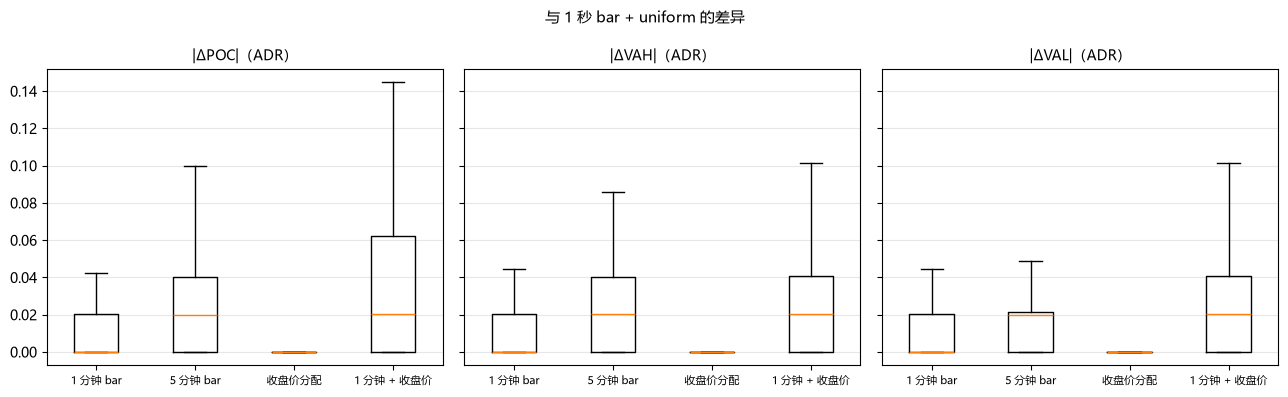

In [7]:
variants = {
    "1 分钟 bar": params.with_(source="1m"),
    "5 分钟 bar": params.with_(source="5m"),
    "收盘价分配": params.with_(distribution="close"),
    "1 分钟 + 收盘价": params.with_(source="1m", distribution="close"),
}
cmp_method = {name: vpf.compare(symbols, start_date, end_date, p) for name, p in variants.items()}
display(P.sensitivity_table(cmp_method).round(3))
show(P.fig_sensitivity(cmp_method, "与 1 秒 bar + uniform 的差异"))

差异最大的几天：分布上有两个差不多高的峰，或者顶部很平、几个格子的成交量接近，粒度一变 POC 就换到另一个位置（2026-07 ~ 10 的 5 分钟对比里，POC 差超过 0.1 ADR 的日子 44% 是双峰日，全部日子里双峰日占 27%）。价值区边缘稳定得多。

In [8]:
worst = cmp_method["5 分钟 bar"].assign(abs_d=lambda d: d["d_poc_adr"].abs())
cols = ["symbol", "date", "adr", "poc_a", "poc_b", "d_poc_adr"]
display(worst.nlargest(8, "abs_d")[cols].round(3))

,symbol,date,adr,poc_a,poc_b,d_poc_adr
208,META,2026-09-21,18.190,699.850,744.990,2.482
379,SPY,2026-10-16,5.825,769.495,762.535,-1.195
455,QQQ,2026-10-16,7.419,718.570,710.320,-1.112
436,QQQ,2026-09-21,6.474,735.080,741.710,1.024
131,AMD,2026-09-18,16.540,559.465,544.165,-0.925
151,AMD,2026-10-16,18.880,529.145,542.825,0.725
367,SPY,2026-09-30,4.700,763.945,766.745,0.596
211,META,2026-09-24,20.770,777.625,766.285,-0.546


## 4. 格子大小敏感性

`bin_adr_frac` = 0.01 / 0.05 与默认 0.02 比较。

,天数,poc 中位数,poc 90 分位,poc >0.1 ADR,vah 中位数,vah 90 分位,vah >0.1 ADR,val 中位数,val 90 分位,val >0.1 ADR
对比,,,,,,,,,,
格子 0.01 ADR,456,0.005,0.063,0.070,0.013,0.042,0.039,0.012,0.049,0.037
格子 0.05 ADR,456,0.015,0.064,0.077,0.032,0.085,0.075,0.031,0.088,0.070


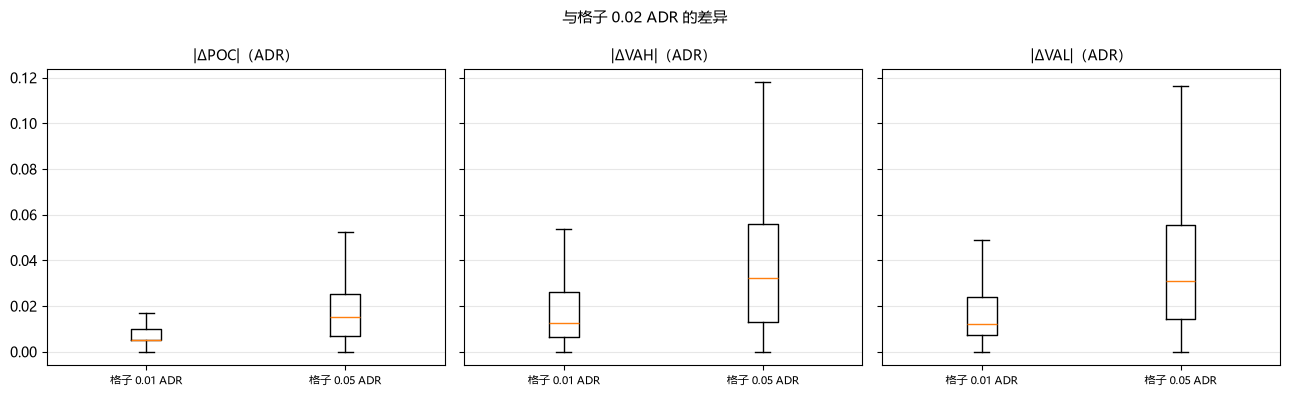

In [9]:
cmp_bin = {
    f"格子 {f} ADR": vpf.compare(symbols, start_date, end_date, params.with_(bin_adr_frac=f))
    for f in (0.01, 0.05)
}
display(P.sensitivity_table(cmp_bin).round(3))
show(P.fig_sensitivity(cmp_bin, "与格子 0.02 ADR 的差异"))

## 5. 形态指标分布

各证券前一日 Profile 的价值区宽度（ADR 倍数）、POC 在当天价格区间中的位置（偏上为 P 形、偏下为 b 形）、HVN 个数（≥ 2 为多峰）。

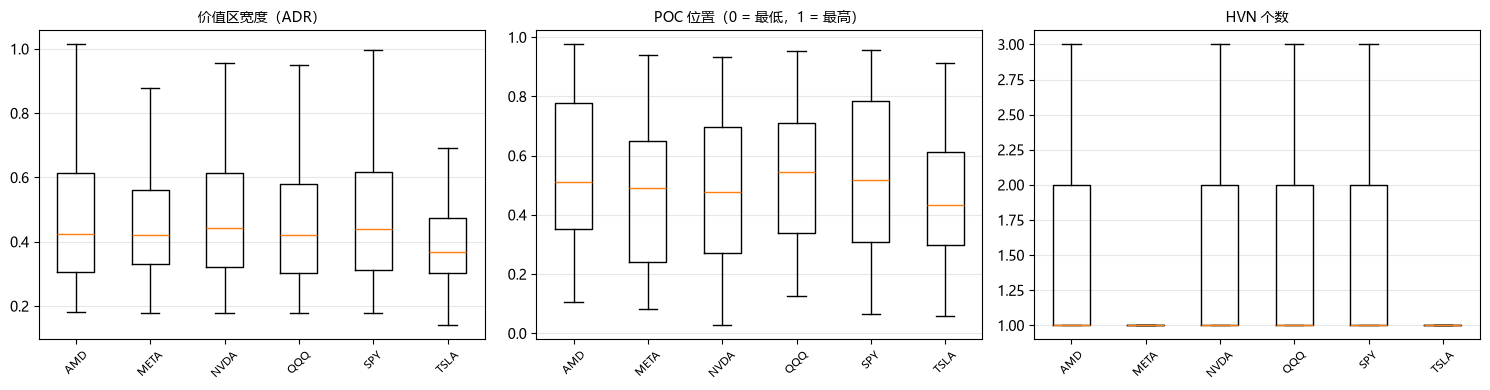

,va_width_adr,poc_position,multi_peak,days
symbol,,,,
AMD,0.42,0.51,0.26,76
META,0.42,0.49,0.22,76
NVDA,0.44,0.48,0.34,76
QQQ,0.42,0.55,0.26,76
SPY,0.44,0.52,0.33,76
TSLA,0.37,0.43,0.16,76


In [10]:
levels = vpf.levels_table(symbols, start_date, end_date, [("daily", {})])
show(P.fig_shape(levels))
summary = levels.groupby("symbol").agg(
    va_width_adr=("va_width_adr", "median"),
    poc_position=("poc_position", "median"),
    multi_peak=("n_hvn", lambda x: (x >= 2).mean()),
    days=("date", "count"),
)
display(summary.round(2))

## 6. 拆股检查（KORU 2026-07-15，1 拆 20）

拆股前后的复合 Profile 应在同一价格口径下连续：拆股后第 2 天的 5 日复合 Profile 包含拆股前 3 天，价格都应在拆股后的区间。

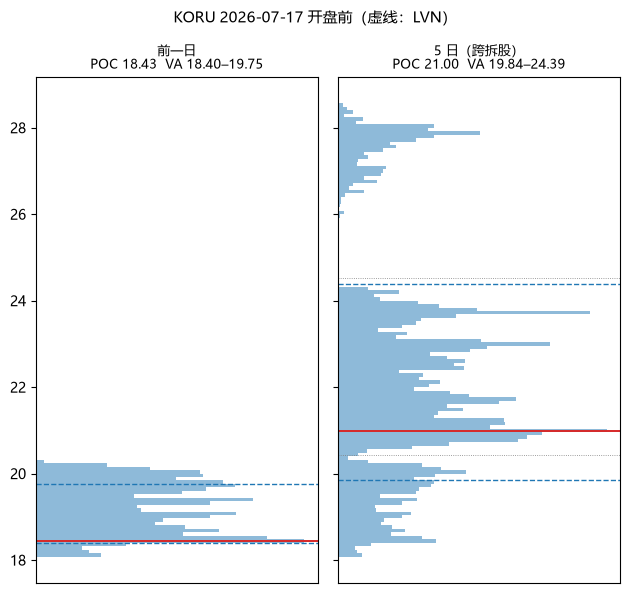

In [11]:
koru = [("前一日", "daily", {}), ("5 日（跨拆股）", "composite", {"n": 5})]
show(P.fig_windows(vpf, "KORU", "2026-07-17", koru))